In [4]:
import ee
import geemap
import geopandas as gpd
import numpy as np
import pandas as pd
import rasterio
import glob
import os
import warnings
import matplotlib
import fiona
matplotlib.use("Agg")          # sin GUI, guarda figuras a disco
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap, BoundaryNorm
from rasterio.merge import merge
from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterio.mask import mask
from rasterio.plot import plotting_extent
from scipy.stats import linregress
from whitebox.whitebox_tools import WhiteboxTools
 
warnings.filterwarnings("ignore")

# PROCESS

In [ ]:
# =============================================================================
# PIPELINE MORFOMÉTRICO E HIDROLÓGICO — ITERACIÓN POR POLÍGONO DE SHAPEFILE
# =============================================================================
# Calcula por cada cuenca/polígono:
#   • Leyes de Horton: Rb, RL, RA (por orden y promedio) + R² regresión
#   • Análisis multifractal: Δα y f(α)_max
#   • Área de la cuenca (km²) y orden Strahler máximo
# Exporta todos los resultados en un Excel resumen.
# =============================================================================

In [5]:
# =============================================================================
# ── DESCARGA Y PREPARACIÓN DEL DEM ───────────────────────────────────────────
# =============================================================================

def _create_ee_grid(roi_ee, nx=6, ny=6):
    bounds = roi_ee.bounds()
    coords = ee.List(bounds.coordinates().get(0))
    xmin = ee.Number(ee.List(coords.get(0)).get(0))
    ymin = ee.Number(ee.List(coords.get(0)).get(1))
    xmax = ee.Number(ee.List(coords.get(2)).get(0))
    ymax = ee.Number(ee.List(coords.get(2)).get(1))
    dx = xmax.subtract(xmin).divide(nx)
    dy = ymax.subtract(ymin).divide(ny)
    cells = []
    for i in range(nx):
        for j in range(ny):
            tile = ee.Geometry.Rectangle(
                [xmin.add(dx.multiply(i)),   ymin.add(dy.multiply(j)),
                 xmin.add(dx.multiply(i+1)), ymin.add(dy.multiply(j+1))],
                proj=None, geodesic=False)
            cells.append(tile)
    return cells


def _download_dem(roi_ee, basin_dir, nx=6, ny=6):
    """Descarga DEM SRTM, construye mosaico y reproyecta a DST_CRS."""
    dem_ee    = ee.Image("USGS/SRTMGL1_003").clip(roi_ee).unmask()
    tiles     = _create_ee_grid(roi_ee, nx=nx, ny=ny)
    tiles_dir = os.path.join(basin_dir, "tiles")
    os.makedirs(tiles_dir, exist_ok=True)

    for i, tile in enumerate(tiles):
        fname = os.path.join(tiles_dir, f"DEM_tile_{i}.tif")
        try:
            geemap.ee_export_image(dem_ee.clip(tile), filename=fname,
                                   scale=30, region=tile, file_per_band=False)
        except Exception as e:
            print(f"      ⚠  Tile {i} fallido: {e}")

    files = glob.glob(os.path.join(tiles_dir, "*.tif"))
    if not files:
        raise RuntimeError("No se descargaron tiles del DEM.")

    srcs = [rasterio.open(f) for f in files]
    mosaic, tf = merge(srcs)
    meta = srcs[0].meta.copy()
    meta.update({"height": mosaic.shape[1], "width": mosaic.shape[2], "transform": tf})
    for s in srcs:
        s.close()

    raw = os.path.join(basin_dir, "dem_mosaic_raw.tif")
    with rasterio.open(raw, "w", **meta) as dst:
        dst.write(mosaic)

    final = os.path.join(basin_dir, "dem_final.tif")
    with rasterio.open(raw) as src:
        t, w, h = calculate_default_transform(
            src.crs, DST_CRS, src.width, src.height, *src.bounds)
        kw = src.meta.copy()
        kw.update({"crs": DST_CRS, "transform": t, "width": w, "height": h})
        with rasterio.open(final, "w", **kw) as dst:
            for b in range(1, src.count + 1):
                reproject(source=rasterio.band(src, b),
                          destination=rasterio.band(dst, b),
                          src_transform=src.transform, src_crs=src.crs,
                          dst_transform=t, dst_crs=DST_CRS,
                          resampling=Resampling.bilinear)
    return final


def _clip_dem(dem_final, gdf_proj, basin_dir):
    """
    Recorta el DEM al polígono de la cuenca.
    Fuerza float32 + nodata=-9999 para compatibilidad con WhiteboxTools.
    Guarda dem_clip.tif y retorna la ruta.
    """
    out_path = os.path.join(basin_dir, "dem_clip.tif")
    with rasterio.open(dem_final) as src:
        out_img, out_tf = mask(src, gdf_proj.geometry, crop=True)
        meta = src.meta.copy()

    out_img = out_img.astype("float32")
    NODATA  = -9999.0
    out_img[out_img <= -32768] = NODATA        # nodata SRTM → -9999

    meta.update({"dtype": "float32", "nodata": NODATA,
                 "height": out_img.shape[1], "width": out_img.shape[2],
                 "transform": out_tf, "compress": "lzw"})

    with rasterio.open(out_path, "w", **meta) as dst:
        dst.write(out_img)

    valid_px = int(np.sum(out_img[0] != NODATA))
    if valid_px == 0:
        raise RuntimeError("dem_clip.tif no tiene píxeles válidos.")
    print(f"      dem_clip.tif guardado ({valid_px:,} px válidos)")
    return out_path


# =============================================================================
# ── WHITEBOX TOOLS ────────────────────────────────────────────────────────────
# =============================================================================

def _check_wbt(basin_dir, filename, step):
    """Lanza excepción clara si WBT no generó el archivo esperado."""
    path = os.path.join(basin_dir, filename)
    if not os.path.exists(path):
        raise RuntimeError(
            f"WBT falló en '{step}': '{filename}' no fue creado.\n"
            f"Revisa los logs de WBT arriba (verbose=True) para el mensaje exacto.")
    if os.path.getsize(path) < 512:
        raise RuntimeError(
            f"WBT produjo '{filename}' casi vacío en '{step}' "
            f"({os.path.getsize(path)} bytes).")
    return path


def _run_whitebox(wbt, basin_dir, stream_thr):
    """
    Pipeline WBT con verificación de salida en cada paso:
      breach → d8_pointer → flow_acc → extract_streams
      → strahler → vectorizar → flow_length
    Parámetros: nombres exactos según la API de WhiteboxTools.
    """
    # Ruta ABSOLUTA: WBT en Windows necesita rutas sin ambigüedad
    wd = os.path.abspath(basin_dir)
    wbt.set_working_dir(wd)

    # ── Breach depressions ────────────────────────────────────────────────────
    # Parámetro de entrada: 'i'  (NO 'dem')
    print("      WBT: breach_depressions_least_cost...")
    wbt.breach_depressions_least_cost(
        dem="dem_clip.tif", output="dem_breach.tif", dist=50)
    _check_wbt(wd, "dem_breach.tif", "breach_depressions_least_cost")

    # ── D8 Flow Direction ─────────────────────────────────────────────────────
    # Parámetro de entrada: 'dem'
    print("      WBT: d8_pointer...")
    wbt.d8_pointer(dem="dem_breach.tif", output="fdir.tif")
    _check_wbt(wd, "fdir.tif", "d8_pointer")

    # ── Flow Accumulation ─────────────────────────────────────────────────────
    # Parámetro de entrada: 'i'
    print("      WBT: d8_flow_accumulation...")
    wbt.d8_flow_accumulation(i="dem_breach.tif", output="acc.tif")
    _check_wbt(wd, "acc.tif", "d8_flow_accumulation")

    # ── Extracción de corrientes ──────────────────────────────────────────────
    print("      WBT: extract_streams...")
    wbt.extract_streams(
        flow_accum="acc.tif", output="streams.tif", threshold=stream_thr)
    _check_wbt(wd, "streams.tif", "extract_streams")

    # ── Orden Strahler ────────────────────────────────────────────────────────
    print("      WBT: strahler_stream_order...")
    wbt.strahler_stream_order(
        d8_pntr="fdir.tif", streams="streams.tif", output="strahler.tif")
    _check_wbt(wd, "strahler.tif", "strahler_stream_order")

    # ── Vectorizar corrientes ─────────────────────────────────────────────────
    print("      WBT: raster_streams_to_vector...")
    wbt.raster_streams_to_vector(
        streams="strahler.tif", d8_pntr="fdir.tif", output="streams.shp")
    _check_wbt(wd, "streams.shp", "raster_streams_to_vector")

    # ── Longitud de trayectoria de flujo ──────────────────────────────────────
    print("      WBT: downslope_flowpath_length...")
    wbt.downslope_flowpath_length(d8_pntr="fdir.tif", output="flow_length.tif")
    _check_wbt(wd, "flow_length.tif", "downslope_flowpath_length")

    return {
        "dem_clip":    os.path.join(wd, "dem_clip.tif"),
        "dem_breach":  os.path.join(wd, "dem_breach.tif"),
        "fdir":        os.path.join(wd, "fdir.tif"),
        "acc":         os.path.join(wd, "acc.tif"),
        "streams_ras": os.path.join(wd, "streams.tif"),
        "strahler":    os.path.join(wd, "strahler.tif"),
        "streams_vec": os.path.join(wd, "streams.shp"),
        "flowlen":     os.path.join(wd, "flow_length.tif"),
    }


# =============================================================================
# ── PLOTS POR ETAPA ───────────────────────────────────────────────────────────
# =============================================================================

def _save_fig(fig, basin_dir, name):
    path = os.path.join(basin_dir, f"{name}.png")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    print(f"      Plot guardado: {name}.png")
    return path


def plot_dem(paths, gdf_proj, basin_id, basin_dir):
    """Mapa del DEM recortado."""
    with rasterio.open(paths["dem_clip"]) as src:
        dem = src.read(1).astype(float)
        ext = plotting_extent(src)
    dem = np.where(dem <= -9999, np.nan, dem)

    fig, ax = plt.subplots(figsize=(9, 7))
    img = ax.imshow(dem, extent=ext, cmap="terrain",
                    vmin=np.nanpercentile(dem, 2), vmax=np.nanpercentile(dem, 98))
    gdf_proj.boundary.plot(ax=ax, color="black", linewidth=1)
    plt.colorbar(img, ax=ax, label="Elevación (m)")
    ax.set_title(f"DEM — Cuenca {basin_id}", fontsize=13)
    ax.set_xlabel("Este (m)"); ax.set_ylabel("Norte (m)")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    return _save_fig(fig, basin_dir, "01_DEM")


def plot_flow_acc(paths, gdf_proj, basin_id, basin_dir):
    """Mapa de acumulación de flujo (escala log)."""
    with rasterio.open(paths["acc"]) as src:
        out_img, out_tf = mask(src, gdf_proj.geometry, crop=True)
    acc = out_img[0].astype(float)
    acc = np.where(acc <= 0, np.nan, acc)
    ext = plotting_extent(acc, out_tf)

    fig, ax = plt.subplots(figsize=(9, 7))
    img = ax.imshow(np.log1p(acc), cmap="cubehelix", extent=ext)
    gdf_proj.boundary.plot(ax=ax, color="red", linewidth=1.2)
    plt.colorbar(img, ax=ax, label="log(Acumulación de flujo)")
    ax.set_title(f"Flow Accumulation — Cuenca {basin_id}", fontsize=13)
    ax.set_xlabel("Este (m)"); ax.set_ylabel("Norte (m)")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    return _save_fig(fig, basin_dir, "02_FlowAccumulation")


def plot_streams(paths, gdf_proj, basin_id, basin_dir):
    """Mapa de la red de drenaje extraída."""
    with rasterio.open(paths["streams_ras"]) as src:
        out_img, out_tf = mask(src, gdf_proj.geometry, crop=True)
    st = out_img[0].astype(float)
    st = np.where(st <= 0, np.nan, st)
    ext = plotting_extent(st, out_tf)

    fig, ax = plt.subplots(figsize=(9, 7))
    ax.imshow(st, cmap="Blues", extent=ext)
    gdf_proj.boundary.plot(ax=ax, color="red", linewidth=1.2)
    ax.set_title(f"Red de Drenaje — Cuenca {basin_id}", fontsize=13)
    ax.set_xlabel("Este (m)"); ax.set_ylabel("Norte (m)")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    return _save_fig(fig, basin_dir, "03_Streams")


def plot_strahler(paths, gdf_proj, basin_id, basin_dir, min_pixels=10):
    """Mapa de órdenes Strahler con colormap discreto."""
    with rasterio.open(paths["strahler"]) as src:
        out_img, out_tf = mask(src, gdf_proj.geometry, crop=True)
    st = out_img[0].astype(float)
    st = np.where(st <= 0, np.nan, st)
    ext = plotting_extent(st, out_tf)

    orders, counts = np.unique(st[~np.isnan(st)], return_counts=True)
    valid = orders[counts > min_pixels].astype(int)
    if len(valid) == 0:
        return None

    base_cmap = plt.cm.get_cmap("turbo", len(valid))
    cmap = ListedColormap(base_cmap(np.arange(len(valid))))
    bounds_ = np.append(valid, valid[-1] + 1)
    norm = BoundaryNorm(bounds_, cmap.N)

    fig, ax = plt.subplots(figsize=(10, 8))
    ax.set_facecolor("white")
    img = ax.imshow(st, cmap=cmap, norm=norm, extent=ext, interpolation="nearest")
    gdf_proj.boundary.plot(ax=ax, color="black", linewidth=1.2)
    cbar = plt.colorbar(img, ax=ax, ticks=valid)
    cbar.set_label("Orden Strahler")
    ax.set_title(f"Red Horton-Strahler — Cuenca {basin_id}", fontsize=13)
    ax.set_xlabel("Este (m)"); ax.set_ylabel("Norte (m)")
    ax.grid(alpha=0.2)
    plt.tight_layout()
    return _save_fig(fig, basin_dir, "04_Strahler")


def plot_horton_laws(orders, counts, mean_lengths, areas_km2, basin_id, basin_dir):
    """Gráfica combinada de las 3 leyes de Horton."""
    fig, ax1 = plt.subplots(figsize=(9, 6))
    ax1.plot(orders, counts, "-o", linewidth=2, markersize=7, label="N(w)")
    ax1.set_yscale("log")
    ax1.set_xlabel("Orden Strahler", fontsize=11)
    ax1.set_ylabel("Número de corrientes", fontsize=11)

    ax2 = ax1.twinx()
    ax2.plot(orders, mean_lengths, "-s", linewidth=2, markersize=7, label="L(w) (m)")
    ax2.plot(orders, areas_km2,    "-^", linewidth=2, markersize=7, label="A(w) (km²)")
    ax2.set_yscale("log")
    ax2.set_ylabel("Longitud media (m) / Área (km²)", fontsize=11)

    lines1, lab1 = ax1.get_legend_handles_labels()
    lines2, lab2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, lab1 + lab2, loc="upper left")
    ax1.grid(True, which="both", alpha=0.3)
    ax1.set_title(f"Leyes de Horton — Cuenca {basin_id}", fontsize=13)
    plt.tight_layout()
    return _save_fig(fig, basin_dir, "05_HortonLaws")


def plot_width_function(paths, gdf_proj, basin_id, basin_dir):
    """Función de ancho de la cuenca (histograma de flow length)."""
    with rasterio.open(paths["flowlen"]) as src:
        out_img, _ = mask(src, gdf_proj.geometry, crop=True)
    fl = out_img[0].astype(float)
    fl = np.where(fl <= 0, np.nan, fl)
    vals = fl[~np.isnan(fl)]
    if vals.size == 0:
        return None

    hist, edges = np.histogram(vals / 1000, bins=120)
    x = (edges[:-1] + edges[1:]) / 2

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(x, hist, linewidth=2)
    ax.fill_between(x, hist, alpha=0.3)
    ax.set_xlabel("Distancia hidrológica al outlet (km)", fontsize=11)
    ax.set_ylabel("Frecuencia espacial", fontsize=11)
    ax.set_title(f"Función de Ancho — Cuenca {basin_id}", fontsize=13)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    return _save_fig(fig, basin_dir, "06_WidthFunction")


def plot_multifractal(q_valid, tau, alpha, f_alpha, basin_id, basin_dir):
    """Espectro multifractal f(α) vs α."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].plot(q_valid, tau, "-o", linewidth=2, markersize=5)
    axes[0].set_xlabel("q", fontsize=11); axes[0].set_ylabel("τ(q)", fontsize=11)
    axes[0].set_title("Función de partición τ(q)")
    axes[0].grid(alpha=0.3)

    axes[1].plot(alpha, f_alpha, "-o", linewidth=2, markersize=5, color="darkorange")
    axes[1].set_xlabel("α (dimensión de Hölder)", fontsize=11)
    axes[1].set_ylabel("f(α)", fontsize=11)
    axes[1].set_title(f"Espectro Multifractal — Cuenca {basin_id}")
    axes[1].grid(alpha=0.3)

    plt.suptitle(f"Análisis Multifractal — Cuenca {basin_id}", fontsize=13, y=1.01)
    plt.tight_layout()
    return _save_fig(fig, basin_dir, "07_Multifractal")


# =============================================================================
# ── CÁLCULO DE PARÁMETROS ─────────────────────────────────────────────────────
# =============================================================================

def _compute_horton(paths, gdf_proj, basin_id, basin_dir,
                    pixel_size=30, min_pixels=10):
    """
    Calcula Rb, RL, RA y R² de Horton. Genera plot y retorna dict.

    Notas metodológicas
    -------------------
    • Rb  — N(w) / N(w+1): conteo de segmentos (corrientes) por orden.
            Se usa el raster Strahler para conteo de píxeles por orden;
            np.unique garantiza orden ascendente → resultado determinista.
    • RL  — L(w+1) / L(w): longitud media por orden desde el shapefile
            vectorial. Se filtra solo los órdenes presentes en 'orders'
            para evitar desalineación.
    • RA  — A(w+1) / A(w): ÁREA DE DRENAJE media por orden, calculada
            desde el flow accumulation (acc.tif). Cada píxel de orden w
            tiene un valor de acumulación = nº de celdas upstream; la
            media por orden * pixel_area da el área drenada media real.
            Este método da RA > 1 (valores típicos 3–8), correcto según
            las leyes de Horton.
    """
    epsg_int = int(DST_CRS.split(":")[1])
    result   = {}

    # ── 1. Leer y limpiar raster Strahler ────────────────────────────────────
    with rasterio.open(paths["strahler"]) as src:
        st_img, _ = mask(src, gdf_proj.geometry, crop=True)
    st = st_img[0].astype(float)
    st = np.where(st <= 0, np.nan, st)

    # np.unique devuelve siempre orden ascendente → determinista
    orders_raw, counts_raw = np.unique(
        st[~np.isnan(st)].astype(int), return_counts=True)
    valid_mask = counts_raw > min_pixels
    orders = orders_raw[valid_mask]          # int array, ascendente
    counts = counts_raw[valid_mask]

    if len(orders) < 2:
        return None

    result["strahler_max"] = int(orders.max())

    # ── 2. Rb — Razón de Bifurcación ─────────────────────────────────────────
    # Rb(w) = N(w) / N(w+1)  →  siempre > 1
    Rb = {}
    for i in range(len(orders) - 1):
        key = f"Rb_{orders[i]}_{orders[i+1]}"
        Rb[key] = round(float(counts[i] / counts[i+1]), 4)
    result["Rb_mean"] = round(float(np.mean(list(Rb.values()))), 4)
    result.update(Rb)

    # R² regresión log-lineal N(w) ~ orden (Ley de Horton)
    _, _, r_val, _, _ = linregress(orders.astype(float), np.log10(counts.astype(float)))
    result["Rb_R2"] = round(float(r_val**2), 4)

    # ── 3. RL — Razón de Longitudes (método raster con ndimage) ─────────────
    #
    # PROBLEMA DEL VECTOR: raster_streams_to_vector de WBT emite 1 feature
    # por pixel (~30m), no 1 feature por reach completo (junction-to-junction).
    # Resultado: mean(length_m) ≈ 30m para todos los órdenes → RL ≈ 1.0.
    #
    # SOLUCIÓN ROBUSTA — directo desde el raster Strahler:
    #   1. total_length(w)  = n_pixels(w) * pixel_size          [determinista]
    #   2. n_reaches(w)     = componentes conectados en orden w  [ndimage.label]
    #   3. mean_length(w)   = total_length(w) / n_reaches(w)
    #   4. RL(w)            = mean_length(w+1) / mean_length(w) → esperable > 1
    #
    # Conectividad 8 (diagonal) porque corrientes raster se conectan en diagonal.
    from scipy import ndimage as ndi
    struct8 = ndi.generate_binary_structure(2, 2)   # conectividad 8

    mean_length_raster = {}   # orden → longitud media de reach (m)
    n_reaches_by_order = {}
    for o in orders:
        binary = (st == o)
        labeled, n_comp = ndi.label(binary, structure=struct8)
        n_px   = int(binary.sum())
        n_reaches_by_order[o] = n_comp
        if n_comp > 0:
            mean_length_raster[o] = (n_px * pixel_size) / n_comp
        else:
            mean_length_raster[o] = 0.0

    RL = {}
    for i in range(len(orders) - 1):
        o_curr = int(orders[i]);  o_next = int(orders[i+1])
        l_curr = mean_length_raster.get(o_curr, 0)
        l_next = mean_length_raster.get(o_next, 0)
        if l_curr > 0:
            RL[f"RL_{o_curr}_{o_next}"] = round(float(l_next / l_curr), 4)
    result["RL_mean"] = round(float(np.mean(list(RL.values()))), 4) if RL else np.nan
    result.update(RL)

    # Guardar también el nº de reaches por orden (útil para diagnóstico)
    for o, nr in n_reaches_by_order.items():
        result[f"N_reaches_{o}"] = int(nr)

    # Alias para el plot (mismo array que antes, ahora desde raster)
    mean_lengths_series = {o: mean_length_raster[o] for o in orders}

    # ── 4. RA — Razón de Áreas de Drenaje ────────────────────────────────────
    # MÉTODO CORRECTO: usar flow accumulation como proxy de área drenada.
    # acc[pixel] = nº de celdas upstream → * pixel_area = área drenada (m²).
    # La media por orden da el área de drenaje característica de cada orden.
    # RA(w) = mean_area(w+1) / mean_area(w)  →  debe ser > 1.
    with rasterio.open(paths["acc"]) as src:
        acc_img, _ = mask(src, gdf_proj.geometry, crop=True)
    acc = acc_img[0].astype(float)
    acc = np.where(acc <= 0, np.nan, acc)

    # Área de drenaje media por orden (m²)
    mean_drain_area = {}
    for o in orders:
        px_mask = (st == o)
        if px_mask.sum() > 0:
            mean_drain_area[o] = float(np.nanmean(acc[px_mask])) * (pixel_size**2)

    RA = {}
    mean_drain_km2 = {}
    for i in range(len(orders) - 1):
        o_curr = int(orders[i])
        o_next = int(orders[i+1])
        if o_curr in mean_drain_area and o_next in mean_drain_area:
            a_curr = mean_drain_area[o_curr]
            a_next = mean_drain_area[o_next]
            mean_drain_km2[o_curr] = a_curr / 1e6
            mean_drain_km2[o_next] = a_next / 1e6
            if a_curr > 0:
                RA[f"RA_{o_curr}_{o_next}"] = round(float(a_next / a_curr), 4)

    result["RA_mean"] = round(float(np.mean(list(RA.values()))), 4) if RA else np.nan
    result.update(RA)

    # ── 5. Plot leyes de Horton ───────────────────────────────────────────────
    # mean_lengths_series es ahora un dict {orden: long_media_m}
    ml_aligned = np.array([
        mean_lengths_series.get(int(o), np.nan)
        for o in orders
    ])
    da_aligned = np.array([
        mean_drain_km2.get(int(o), np.nan)
        for o in orders
    ])
    plot_horton_laws(orders, counts, ml_aligned, da_aligned, basin_id, basin_dir)

    return result


def _compute_multifractal(paths, gdf_proj, basin_id, basin_dir):
    """Calcula espectro multifractal del flow accumulation. Genera plot."""
    with rasterio.open(paths["acc"]) as src:
        acc_img, _ = mask(src, gdf_proj.geometry, crop=True)
    acc = acc_img[0].astype(float)
    acc = np.where(acc <= 0, np.nan, acc)
    mu  = acc / np.nansum(acc)

    q_vals = np.arange(-5, 6)
    tau, q_valid_lst = [], []
    eps = 1 / mu.size

    for q in q_vals:
        if q == 1:
            continue
        chi_q = np.nansum(mu**q)
        if chi_q <= 0:
            continue
        tau.append(np.log(chi_q) / np.log(eps))
        q_valid_lst.append(q)

    tau     = np.array(tau)
    q_valid = np.array(q_valid_lst)
    alpha   = np.gradient(tau, q_valid)
    f_alpha = q_valid * alpha - tau

    plot_multifractal(q_valid, tau, alpha, f_alpha, basin_id, basin_dir)

    return {
        "delta_alpha": round(float(alpha.max() - alpha.min()), 6),
        "f_alpha_max": round(float(f_alpha.max()), 6),
    }


# =============================================================================
# ── FUNCIÓN PRINCIPAL POR CUENCA ──────────────────────────────────────────────
# =============================================================================

def process_basin(basin_id, gdf_basin, output_dir, wbt,
                  pixel_size=30, stream_thr=1000, nx=6, ny=6, min_pixels=10):
    """
    Ejecuta el pipeline completo para una sola cuenca/polígono y genera
    todos los mapas intermedios como archivos PNG.

    Retorna dict con los parámetros estimados, o None si falla.
    """
    print(f"\n{'═'*60}")
    print(f"  Cuenca: {basin_id}")
    print(f"{'═'*60}")

    basin_dir = os.path.abspath(os.path.join(output_dir, str(basin_id)))
    os.makedirs(basin_dir, exist_ok=True)

    epsg_int  = int(DST_CRS.split(":")[1])
    gdf_proj  = gdf_basin.to_crs(epsg=epsg_int)
    gdf_wgs84 = gdf_basin.to_crs(epsg=4326)
    roi_ee    = geemap.gdf_to_ee(gdf_wgs84).geometry()

    # ── 1. DEM ────────────────────────────────────────────────────────────────
    print("\n  [1/5] Descargando DEM desde Google Earth Engine...")
    dem_final = _download_dem(roi_ee, basin_dir, nx=nx, ny=ny)

    # ── 2. Recorte ────────────────────────────────────────────────────────────
    print("\n  [2/5] Recortando y preparando DEM...")
    _clip_dem(dem_final, gdf_proj, basin_dir)
    plot_dem({"dem_clip": os.path.join(basin_dir, "dem_clip.tif")},
             gdf_proj, basin_id, basin_dir)

    # ── 3. WhiteboxTools ──────────────────────────────────────────────────────
    print("\n  [3/5] Ejecutando WhiteboxTools...")
    paths = _run_whitebox(wbt, basin_dir, stream_thr)

    # Plots intermedios WBT
    plot_flow_acc(paths, gdf_proj, basin_id, basin_dir)
    plot_streams(paths, gdf_proj, basin_id, basin_dir)
    plot_strahler(paths, gdf_proj, basin_id, basin_dir, min_pixels)
    plot_width_function(paths, gdf_proj, basin_id, basin_dir)

    # ── 4. Leyes de Horton ────────────────────────────────────────────────────
    print("\n  [4/5] Calculando leyes de Horton...")
    horton = _compute_horton(paths, gdf_proj, basin_id, basin_dir,
                             pixel_size, min_pixels)
    if horton is None:
        print(f"  ⚠  Cuenca {basin_id}: orden Strahler insuficiente — se omite.")
        return None

    # ── 5. Multifractal ───────────────────────────────────────────────────────
    print("\n  [5/5] Calculando espectro multifractal...")
    mf = _compute_multifractal(paths, gdf_proj, basin_id, basin_dir)

    area_km2 = round(float(gdf_proj.geometry.area.sum()) / 1e6, 4)

    row = {"basin_id": basin_id, "area_km2": area_km2}
    row.update(horton)
    row.update(mf)

    print(f"\n  ✅ Cuenca {basin_id} completada — plots en: {basin_dir}")
    return row


# =============================================================================
# ── LECTURA DE ARCHIVO VECTORIAL (.shp / .gpkg) ───────────────────────────────
# =============================================================================

def _load_vector(filepath, gpkg_layer=None):
    """
    Carga un archivo vectorial (.shp, .gpkg u otro formato soportado por Fiona)
    y retorna un GeoDataFrame único con todos los polígonos.

    Lógica para GeoPackage
    ----------------------
    Un .gpkg puede tener:
      A) Una sola capa con N features  → lee esa capa directamente.
      B) N capas con 1 feature cada una → concatena todas las capas.
      C) N capas con M features cada una → concatena todo.

    Parámetros
    ----------
    filepath    : ruta al archivo vectorial
    gpkg_layer  : nombre de capa específica (str) o None para leer todas.
    """
    ext = os.path.splitext(filepath)[1].lower()

    # ── Shapefile u otro formato de capa única ────────────────────────────────
    if ext != ".gpkg":
        gdf = gpd.read_file(filepath)
        print(f"  Archivo: {filepath}  ({len(gdf)} polígonos)")
        return gdf.reset_index(drop=True)

    # ── GeoPackage ────────────────────────────────────────────────────────────
    capas = fiona.listlayers(filepath)
    print(f"\n  GeoPackage: {filepath}")
    print(f"  Capas encontradas ({len(capas)}): {capas}")

    # Capa específica solicitada
    if gpkg_layer is not None:
        gdf = gpd.read_file(filepath, layer=gpkg_layer)
        print(f"  Leyendo capa '{gpkg_layer}': {len(gdf)} polígonos")
        return gdf.reset_index(drop=True)

    # Todas las capas → leer y concatenar
    gdfs = []
    for capa in capas:
        try:
            g = gpd.read_file(filepath, layer=capa)
            if len(g) == 0:
                continue
            g["_gpkg_layer"] = capa   # columna auxiliar con nombre de capa
            gdfs.append(g)
            print(f"    Capa '{capa}': {len(g)} polígono(s)")
        except Exception as e:
            print(f"    Capa '{capa}': error al leer ({e})")

    if not gdfs:
        raise RuntimeError(f"No se pudo leer ninguna capa de '{filepath}'.")

    # Unificar CRS (usar el de la primera capa como referencia)
    crs_ref = gdfs[0].crs
    gdfs_aligned = [
        g.to_crs(crs_ref) if g.crs != crs_ref else g
        for g in gdfs
    ]
    gdf_full = gpd.GeoDataFrame(
        pd.concat(gdfs_aligned, ignore_index=True),
        crs=crs_ref
    )
    print(f"\n  Total polígonos cargados: {len(gdf_full)}")
    return gdf_full


# =============================================================================
# ── ITERACIÓN SOBRE SHAPEFILE ─────────────────────────────────────────────────
# =============================================================================

def run_all_basins(
    shapefile_path,
    output_dir,
    ee_project,
    id_field   = None,
    gpkg_layer = None,
    pixel_size = 30,
    stream_thr = 1000,
    nx         = 6,
    ny         = 6,
    min_pixels = 10,
):
    """
    Itera sobre todos los polígonos de un shapefile, ejecuta el análisis
    morfométrico completo y exporta un Excel resumen con dos hojas:
      • Resumen   — parámetros globales por cuenca
      • Por_Orden — Rb, RL, RA desagregados por par de órdenes

    Los mapas PNG de cada etapa se guardan en output_dir/<basin_id>/.
    """
    print("Autenticando Google Earth Engine...")
    ee.Authenticate(auth_mode='localhost')
    ee.Initialize(project=ee_project)

    wbt = WhiteboxTools()
    wbt.verbose = True    # ← False para suprimir logs de WBT

    os.makedirs(output_dir, exist_ok=True)

    gdf_full = _load_vector(shapefile_path, gpkg_layer)
    n_total  = len(gdf_full)
    print(f"\n📌 {n_total} polígono(s) listos para procesar")

    results = []

    for i in range(n_total):
        # ── Extraer polígono con iloc (preserva geometría sin ambigüedad) ────────
        try:
            row_series = gdf_full.iloc[i]

            # ID de la cuenca
            if id_field and id_field in gdf_full.columns:
                basin_id = row_series[id_field]
            else:
                basin_id = i

            # GeoDataFrame de una sola fila, con CRS y geometría garantizados
            gdf_basin = gdf_full.iloc[[i]].copy().reset_index(drop=True)

        except Exception as e:
            print(f"\n  ❌ Error leyendo polígono {i}: {e}")
            results.append({"basin_id": i, "error": f"Error lectura shapefile: {e}"})
            continue

        # ── Procesar la cuenca ───────────────────────────────────────────────────
        try:
            result = process_basin(
                basin_id   = basin_id,
                gdf_basin  = gdf_basin,
                output_dir = output_dir,
                wbt        = wbt,
                pixel_size = pixel_size,
                stream_thr = stream_thr,
                nx         = nx,
                ny         = ny,
                min_pixels = min_pixels,
            )
            if result is not None:
                results.append(result)

        except Exception as e:
            print(f"\n  ❌ Cuenca {basin_id} falló: {e}")
            results.append({"basin_id": basin_id, "error": str(e)})

        print(f"\n  Progreso: {i + 1}/{n_total}")

        # ── Guardar resultados parciales después de cada cuenca ──────────────────
        # (por si el proceso se interrumpe a mitad)
        if results:
            df_parcial = pd.DataFrame(results)
            df_parcial.to_excel(
                os.path.join(output_dir, "morfometria_parcial.xlsx"),
                index=False
            )

    # ── DataFrame ─────────────────────────────────────────────────────────────
    df = pd.DataFrame(results)

    priority = ["basin_id", "area_km2", "strahler_max",
                "Rb_mean", "RL_mean", "RA_mean",
                "Rb_R2", "delta_alpha", "f_alpha_max", "error"]
    front  = [c for c in priority if c in df.columns]
    detail = sorted([c for c in df.columns if c not in priority])
    df     = df[front + detail]

    # ── Excel ─────────────────────────────────────────────────────────────────
    excel_path = os.path.join(output_dir, "morfometria_resumen.xlsx")
    detail_rb_rl_ra = ["basin_id"] + [
        c for c in detail
        if any(c.startswith(p) for p in ("Rb_", "RL_", "RA_"))
    ]
    with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
        df.to_excel(writer, index=False, sheet_name="Resumen")
        df[detail_rb_rl_ra].to_excel(writer, index=False, sheet_name="Por_Orden")

    print(f"\n{'═'*60}")
    print(f"✅ {len(df)} cuenca(s) procesada(s).")
    print(f"   Excel  →  {excel_path}")
    print(f"   Plots  →  {os.path.abspath(output_dir)}/<basin_id>/*.png")
    print(f"{'═'*60}")

    return df

In [6]:
# =============================================================================
# ── CONFIGURACIÓN ─────────────────────────────────────────────────────────────
# =============================================================================

EE_PROJECT   = "hydro-496000"          # ← ID proyecto Google Earth Engine
SHAPEFILE    = "Orinoco.gpkg"           # ← shapefile con los polígonos
ID_FIELD     = "COD_SZH"              # ← campo identificador (None → usa índice)
GPKG_LAYER   = 'orinoquia_subzone'              # ← capa del GeoPackage (None = todas las capas)
OUTPUT_DIR   = "Results"           # ← carpeta raíz de salida
DST_CRS      = "EPSG:3116"            # ← CRS proyectado del análisis
PIXEL_SIZE   = 30                     # metros (resolución DEM)
STREAM_THR   = 1000                   # umbral acumulación → red de drenaje
MIN_PIXELS   = 10                     # mínimo píxeles por orden Strahler
NX, NY       = 6, 6                   # divisiones de la grilla EE (tiles)

In [8]:
# =============================================================================
# ── PUNTO DE ENTRADA ──────────────────────────────────────────────────────────
# =============================================================================

if __name__ == "__main__":

    df = run_all_basins(
        shapefile_path = SHAPEFILE,
        output_dir     = OUTPUT_DIR,
        ee_project     = EE_PROJECT,
        id_field       = ID_FIELD,
        gpkg_layer     = GPKG_LAYER,
        pixel_size     = PIXEL_SIZE,
        stream_thr     = STREAM_THR,
        nx             = NX,
        ny             = NY,
        min_pixels     = MIN_PIXELS,
    )

    print("\n📊 Vista previa:")
    print(df.to_string(index=False))

Autenticando Google Earth Engine...

  GeoPackage: Orinoco.gpkg
  Capas encontradas (2): ['orinoco', 'orinoquia_subzone']
  Leyendo capa 'orinoquia_subzone': 73 polígonos

📌 73 polígono(s) listos para procesar

════════════════════════════════════════════════════════════
  Cuenca: 3701
════════════════════════════════════════════════════════════

  [1/5] Descargando DEM desde Google Earth Engine...
Generating URL ...
Please wait ...
Data downloaded to e:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Project\Results\3701\tiles\DEM_tile_0.tif
Generating URL ...
Please wait ...
Data downloaded to e:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Project\Results\3701\tiles\DEM_tile_1.tif
Generating URL ...
Please wait ...
Data downloaded to e:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Project\Results\3701\tiles\DEM_tile_2.tif
Generating URL ...
Please wait ...
Data downloaded to e:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Project\Results\3701\tiles\D

# VISUALIZATIONS

In [1]:
import geopandas as gpd
import pandas as pd

In [2]:
# =========================
# 1. Rutas de archivos
# =========================
gpkg_path = r"./Orinoco.gpkg"
excel_path = r"./Results/morfometria_resumen.xlsx"

# =========================
# 2. Nombre de la capa
# =========================
layer_name = "orinoquia_subzone"

# =========================
# 3. Leer capa del GeoPackage
# =========================
gdf = gpd.read_file(gpkg_path, layer=layer_name)


# =========================
# 4. Leer archivo Excel
# =========================
df_excel = pd.read_excel(excel_path)

# =========================
# 5. Unir usando campo común
# =========================
# Ejemplo:
# campo en geopackage = "ID"
# campo en excel = "ID"

gdf_merge = gdf.merge(
    df_excel,
    left_on="COD_SZH",   # campo del GPKG
    right_on="basin_id",      # campo del Excel
    how="left"
)


In [3]:
gdf_merge.head()

,OBJECTID_1,COD_AH,COD_ZH,COD_SZH,NOM_AH,NOM_ZH,NOM_SZH,Shape_Leng,Shape_Area,RULEID,...,RL_3_4,RL_4_5,RL_5_6,RL_6_7,Rb_1_2,Rb_2_3,Rb_3_4,Rb_4_5,Rb_5_6,Rb_6_7
0,37,3,37,3701,Orinoco,Arauca,Río Chítaga,3.033020,0.203615,4,...,2.7948,5.9934,NaN,NaN,2.0632,2.0850,2.3615,0.8342,NaN,NaN
1,38,3,37,3702,Orinoco,Arauca,Río Margua,1.322978,0.061035,4,...,2.4335,1.9365,NaN,NaN,2.6317,1.7574,1.3355,2.0656,NaN,NaN
2,40,3,37,3703,Orinoco,Arauca,Río Cobugón - Río Cobaría,1.844153,0.161766,4,...,2.3737,4.1887,NaN,NaN,2.3503,1.6479,2.1064,1.1937,NaN,NaN
3,41,3,39,3901,Orinoco,Apure,Alto Río Apure,0.967064,0.021619,4,...,NaN,NaN,NaN,NaN,2.0320,2.1179,NaN,NaN,NaN,NaN
4,42,3,35,3507,Orinoco,Meta,Río Garagoa,2.826144,0.202833,4,...,2.2976,5.3010,0.5946,NaN,2.1633,2.6369,2.1762,1.1319,1.6819,NaN


In [4]:
columnas = [
    "COD_AH",
    "COD_ZH",
    "COD_SZH",
    "NOM_AH",
    "NOM_ZH",
    "area_km2",
    "strahler_max",
    "Rb_mean",
    "RL_mean",
    "RA_mean",
    "delta_alpha",
    "geometry"
]

gdf_sel = gdf_merge[columnas]

In [5]:
output_path = r"./Results/Final_data.gpkg"

gdf_sel.to_file(
    output_path,
    layer="final_data",
    driver="GPKG"
)

print(f"Archivo guardado en: {output_path}")

Archivo guardado en: ./Results/Final_data.gpkg


In [6]:
import matplotlib.pyplot as plt
from matplotlib_scalebar.scalebar import ScaleBar

%matplotlib inline

vars_grupo1 = [
    "strahler_max",
    "delta_alpha"
]

vars_grupo2 = [
    "Rb_mean",
    "RL_mean",
    "RA_mean"
]

plt.rcParams.update({
    "font.size": 10,
    "font.family": "serif",
    "axes.titlesize": 12,
    "figure.titlesize": 14
})

In [ ]:
def plot_q1_maps(gdf, variables, titulo_general):

    n = len(variables)

    fig, axes = plt.subplots(
        n,
        1,
        figsize=(6, 6*n),
        dpi=300
    )

    if n == 1:
        axes = [axes]

    for ax, var in zip(axes, variables):

        # ==============================
        # MAPA
        # ==============================

        gdf.plot(
            column=var,
            cmap='Spectral_r',
            scheme="quantiles",
            k=5,
            linewidth=0.35,
            edgecolor="black",
            legend=True,
            ax=ax
        )

        # ==============================
        # ETIQUETAS
        # ==============================

        for idx, row in gdf.iterrows():

            if row.geometry is not None:

                centroid = row.geometry.centroid

                ax.text(
                    centroid.x,
                    centroid.y,
                    str(row["COD_SZH"]),
                    fontsize=4,
                    ha="center",
                    color="black"
                )

        # ==============================
        # GRILLA
        # ==============================

        ax.grid(
            True,
            linestyle=":",
            linewidth=0.3,
            alpha=0.4
        )

        # ==============================
        # TÍTULO
        # ==============================

        ax.set_title(
            var.replace("_", " "),
            pad=6,
            fontweight="bold"
        )

        # ==============================
        # LIMPIAR EJES
        # ==============================

        ax.set_xlabel("")
        ax.set_ylabel("")

    # ==================================
    # TÍTULO GENERAL
    # ==================================

    fig.suptitle(
        titulo_general,
        fontweight="bold",
        y=0.98
    )

    plt.tight_layout()

    plt.show()

c:\Users\waleonr\anaconda3\envs\hydro_f\Lib\site-packages\mapclassify\classifiers.py:1767: UserWarning: Not enough unique values in array to form 5 classes. Setting k to 3.
  self.bins = quantile(y, k=k)


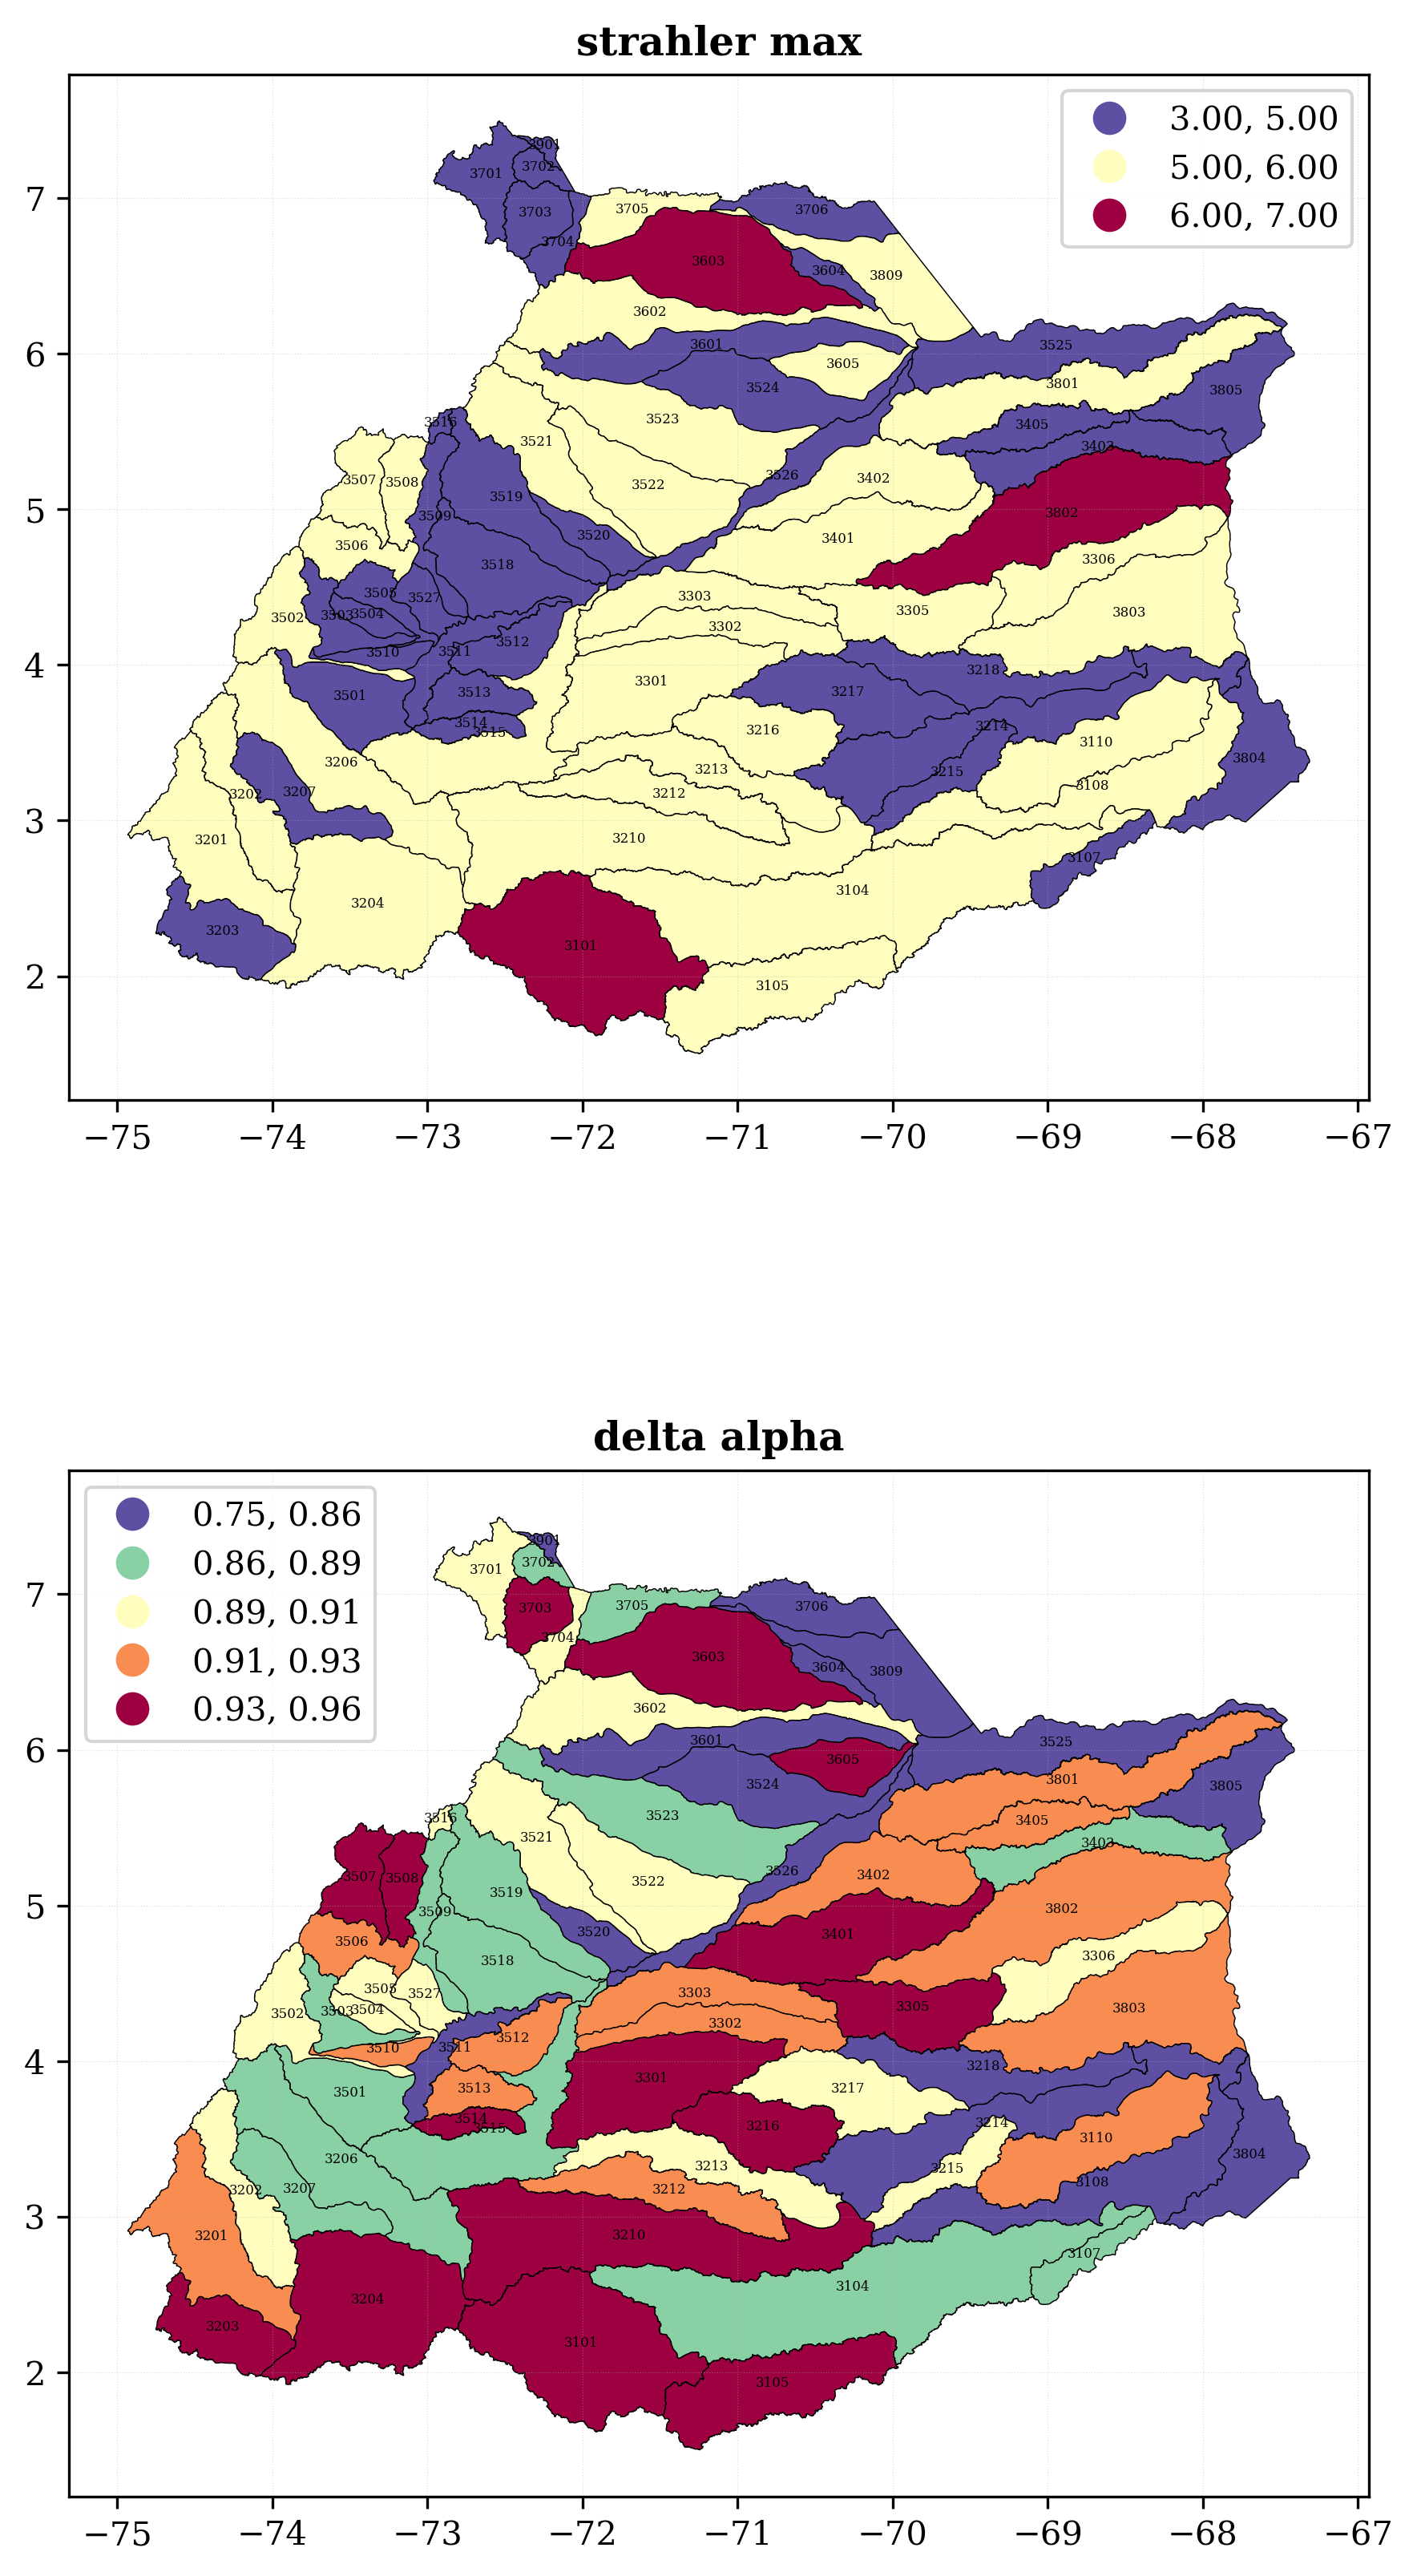

In [12]:
plot_q1_maps(
    gdf_sel,
    vars_grupo1,
    ""
)

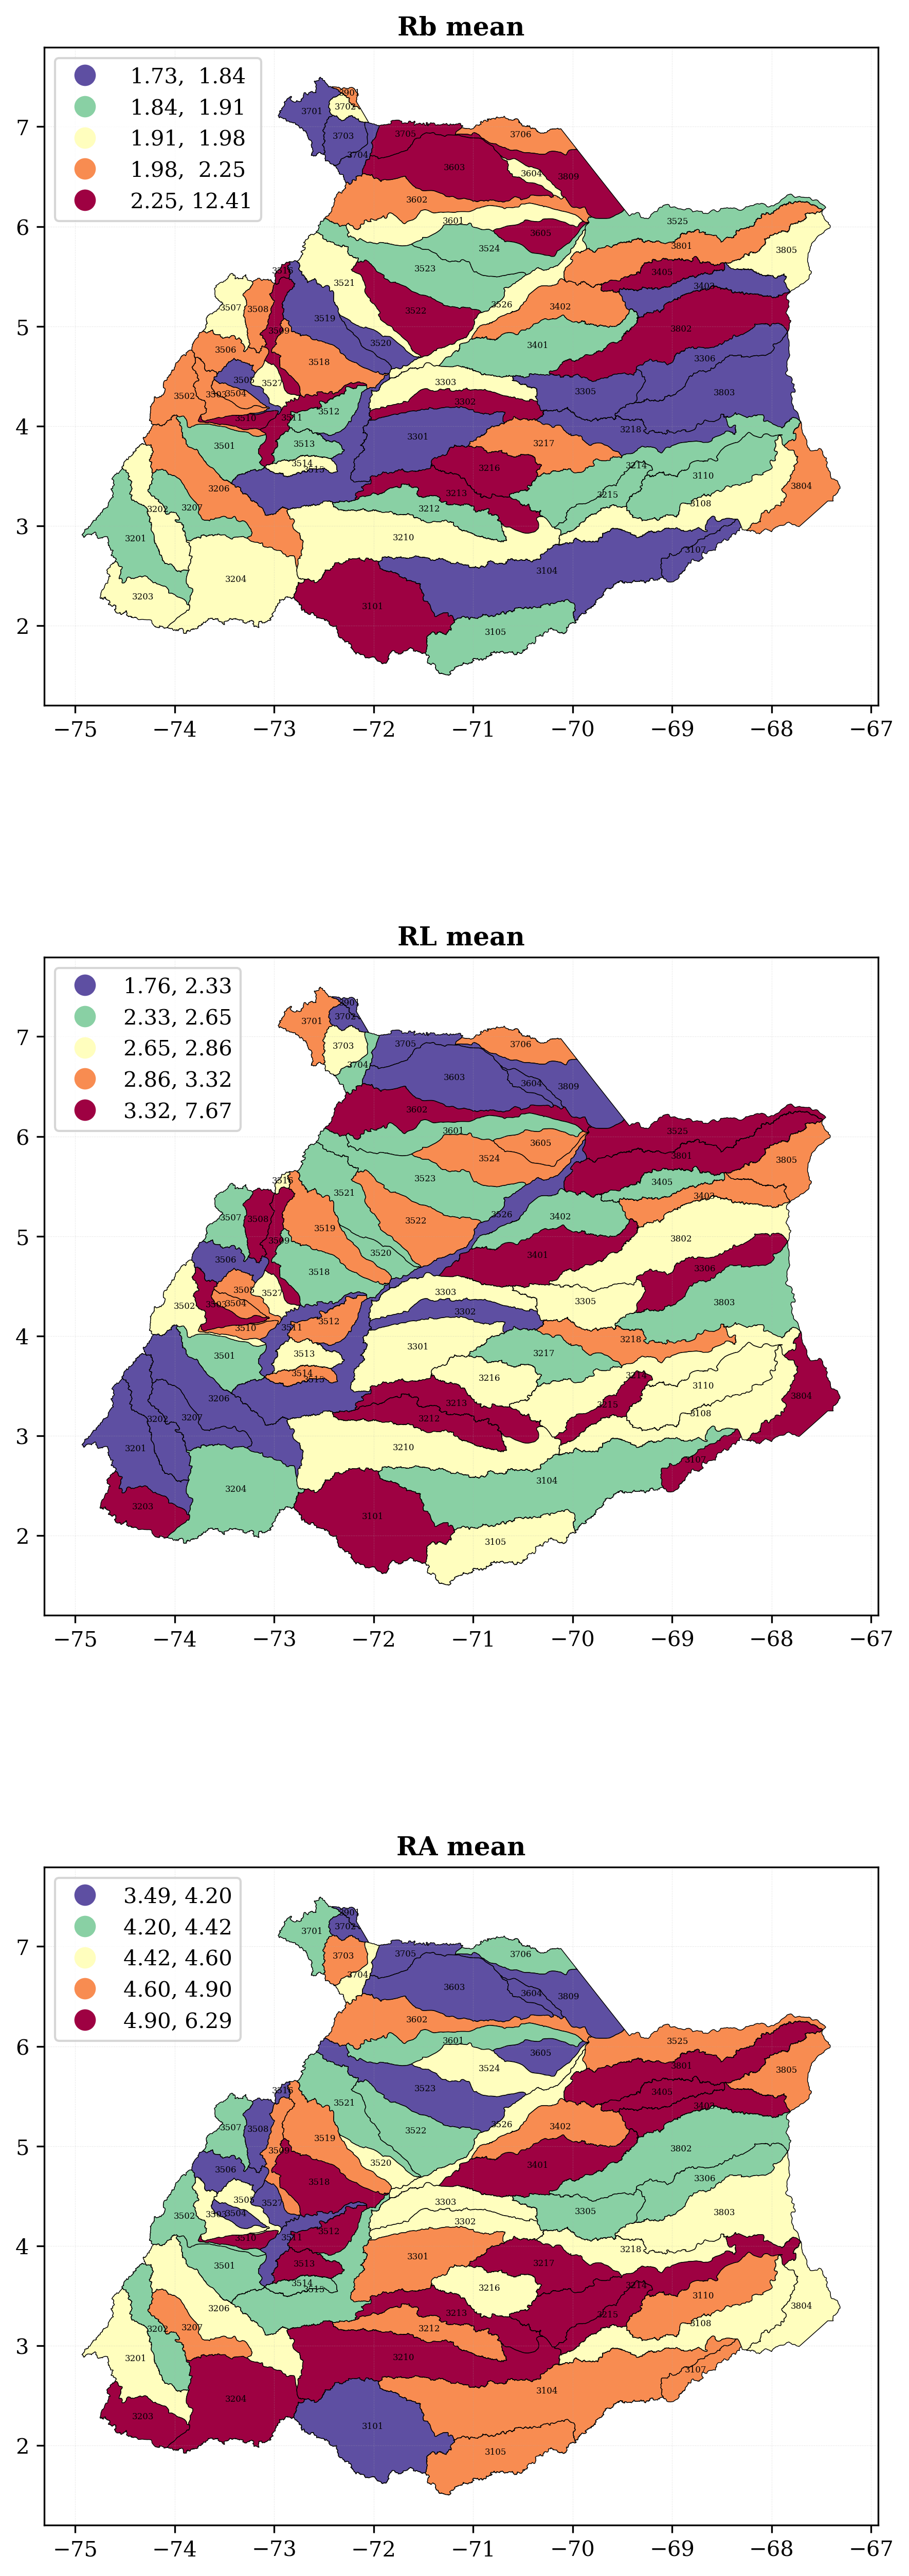

In [13]:
plot_q1_maps(
    gdf_sel,
    vars_grupo2,
    ""
)

In [14]:
vars_grupo3 = [
    "area_km2"
]

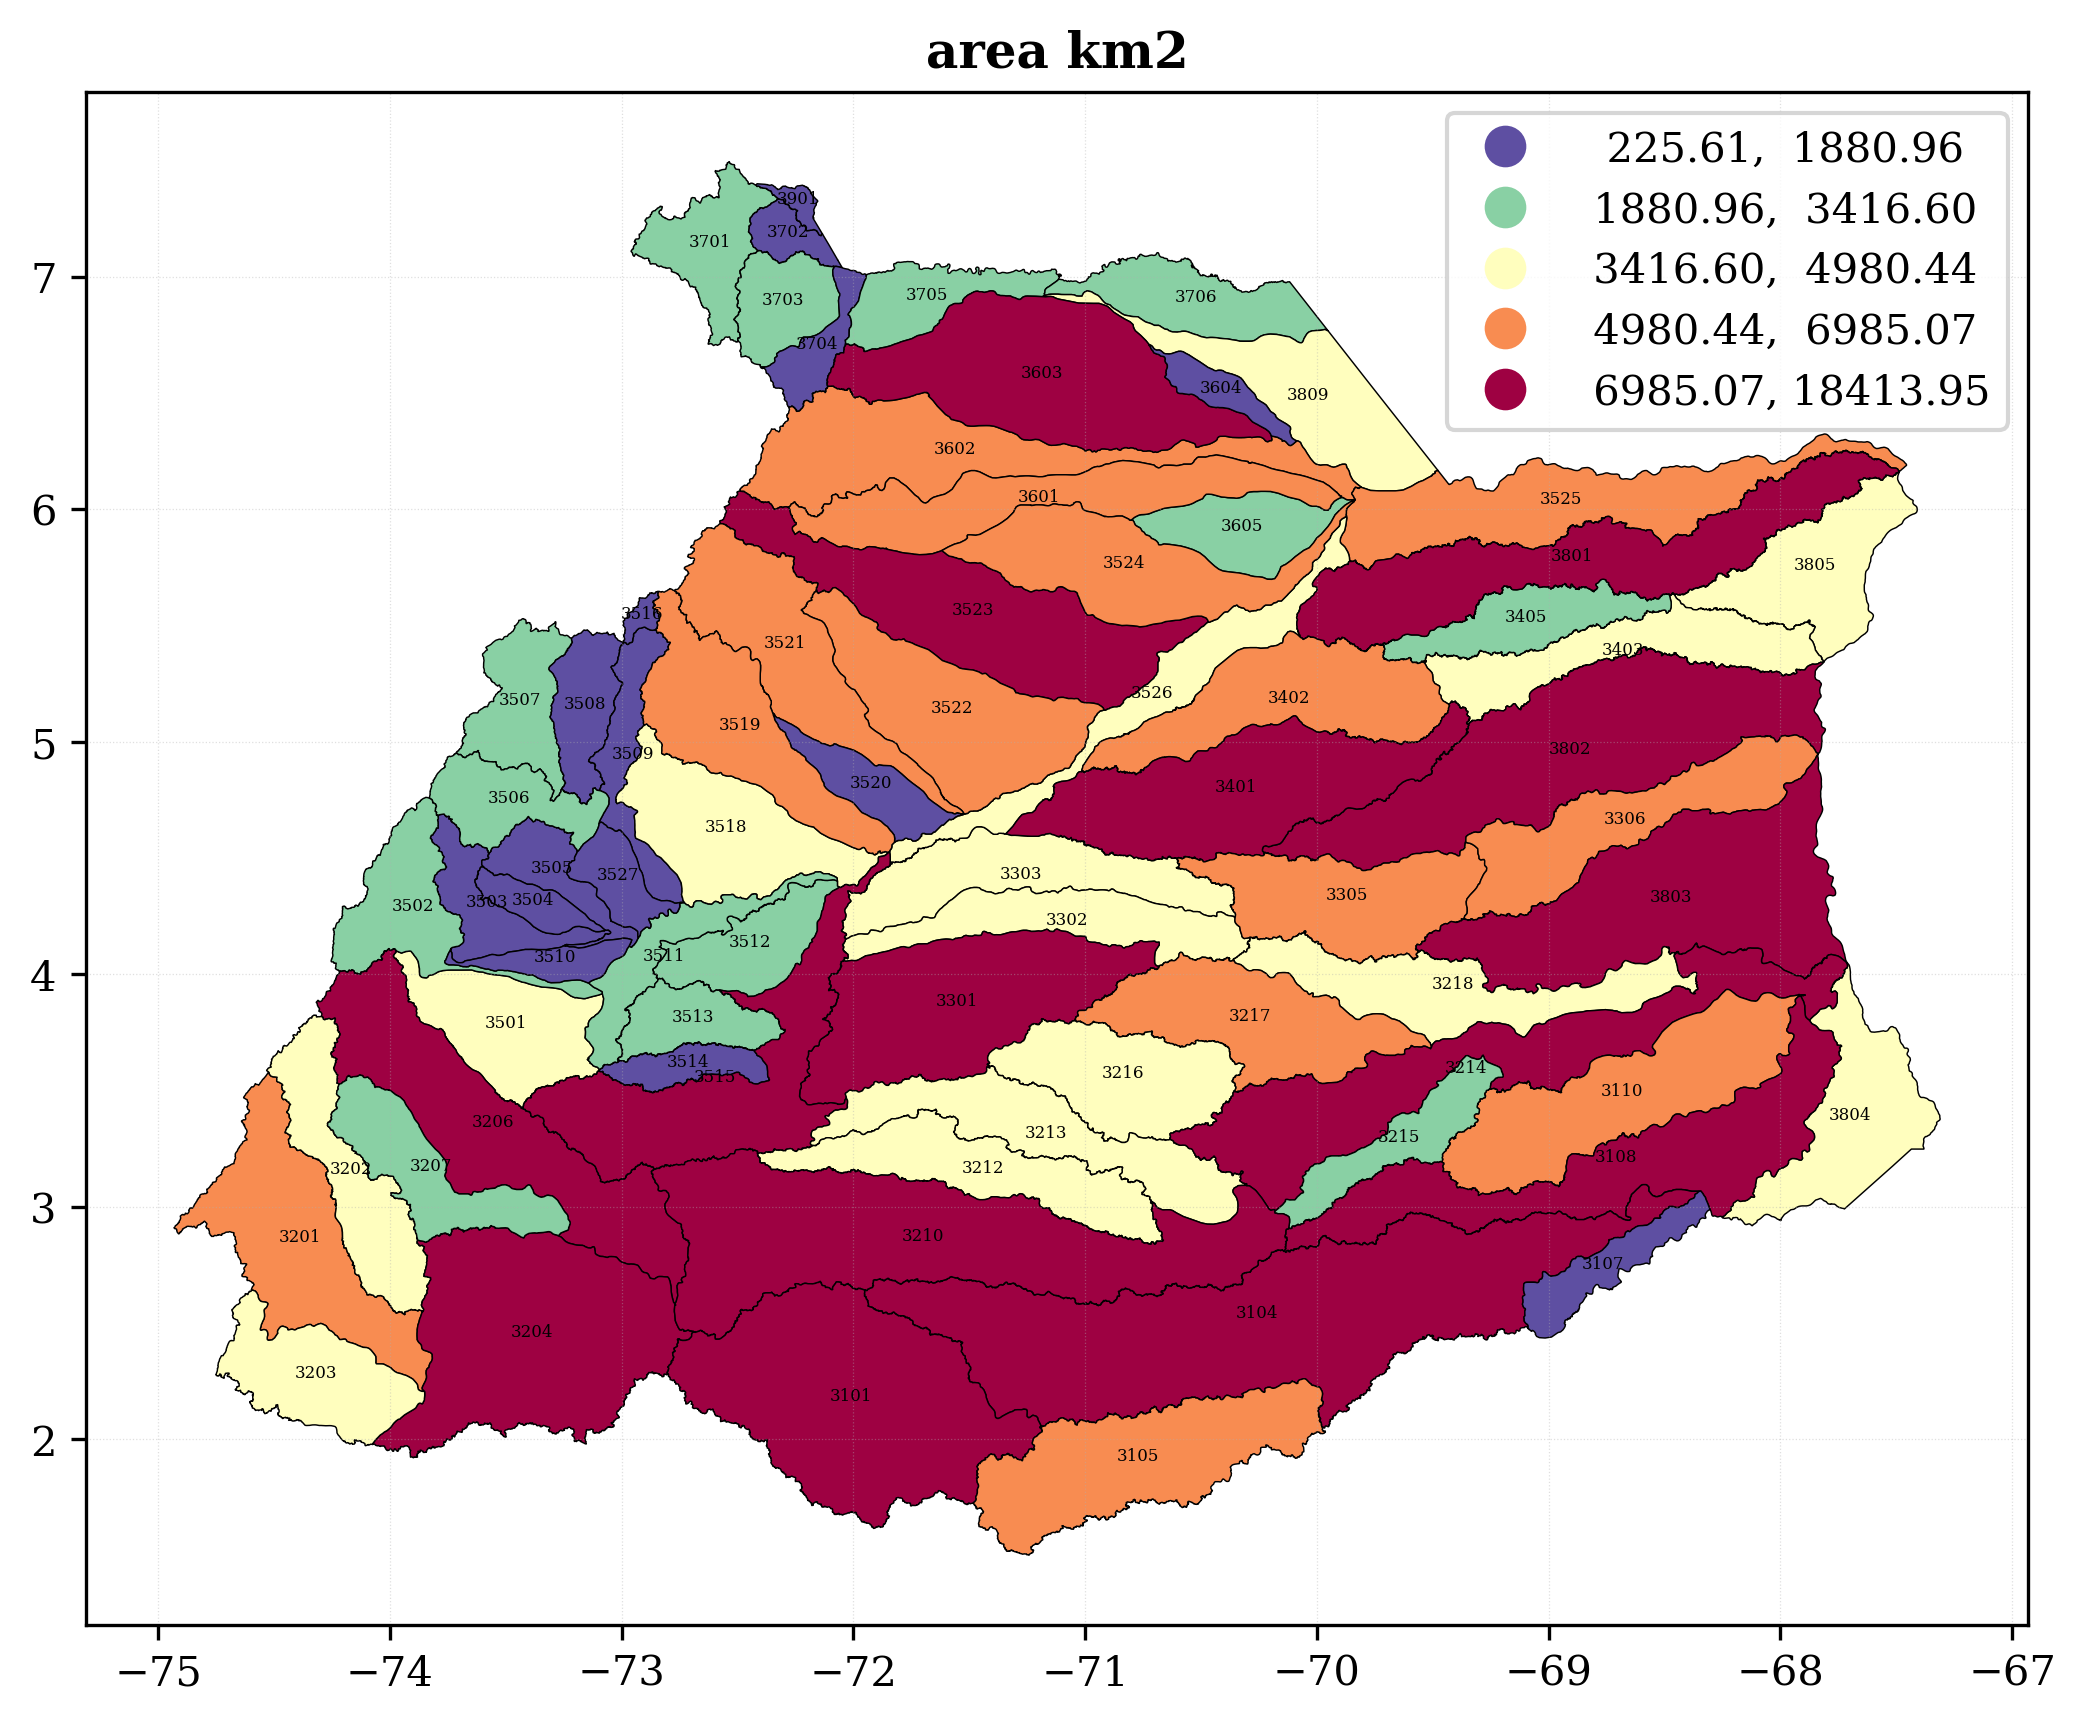

In [17]:
plot_q1_maps(
    gdf_sel,
    vars_grupo3,
    ""
)